In [18]:
# 07 — NLP Intent Recognition and Entity Extraction

## Project Objective
# Build an NLP system that can:
# - Understand user messages.
# - Identify user intents.
# - Extract important entities.
# - Prepare for contextual conversation handling.

# ## NLP Techniques
# - Text preprocessing
# - TF-IDF Vectorization
# - Logistic Regression
# - Linear Support Vector Machine
# - Named Entity Recognition (NER)
# - Model evaluation

In [19]:
# NLP and data processing libraries

import pandas as pd
import numpy as np
import re
import json
import random
from pathlib import Path

# Machine Learning libraries

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC

# Model evaluation

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# Visualization

import matplotlib.pyplot as plt

# Display settings

pd.set_option("display.max_colwidth", 120)

print("NLP libraries imported successfully.")

NLP libraries imported successfully.


In [20]:
# Create a separate, project-generated chatbot intent dataset

intent_examples = {
    "greeting": [
        "Hello", "Hi there", "Hey", "Good morning",
        "Good afternoon", "Good evening", "Hello chatbot",
        "Hi, how are you?", "Hey there", "Greetings",
        "Is anyone there?", "I want to say hello",
        "How is your day?", "Hi, can you help me?",
        "Hello, are you available?"
    ],

    "goodbye": [
        "Goodbye", "Bye", "See you later", "Talk to you soon",
        "Have a nice day", "I am leaving now", "Catch you later",
        "That is all for now", "See you tomorrow",
        "I have to go", "Thanks, bye", "End this conversation",
        "Take care", "Until next time", "Farewell"
    ],

    "thanks": [
        "Thank you", "Thanks a lot", "That was helpful",
        "I appreciate your help", "Many thanks",
        "Thanks for the information", "You helped me",
        "Great, thank you", "I am grateful",
        "Thanks for explaining", "That solved my problem",
        "Appreciate it", "Thank you so much",
        "This was useful", "Thanks for your support"
    ],

    "bot_identity": [
        "Who are you?", "What is your name?",
        "Are you a chatbot?", "What can I call you?",
        "Tell me about yourself", "Are you a human?",
        "Are you an AI assistant?", "Who created you?",
        "What type of assistant are you?",
        "Are you a virtual assistant?",
        "Can you introduce yourself?",
        "What are you?", "Do you use artificial intelligence?",
        "Are you a real person?", "Tell me your identity"
    ],

    "help": [
        "I need help", "Can you help me?",
        "What can you do?", "Show me how to use this chatbot",
        "I need some assistance", "How does this work?",
        "Can you guide me?", "I am confused",
        "Please explain your features", "Help me get started",
        "What services can you provide?",
        "I need guidance", "Can you assist me?",
        "Tell me how to proceed", "I need some information"
    ],

    "faq_hours": [
        "What are your working hours?",
        "When are you available?", "What time do you open?",
        "What time do you close?", "Are you available today?",
        "Tell me your business hours", "When can I contact support?",
        "Do you work on weekends?", "Are you open on Sunday?",
        "What are your operating hours?",
        "When does customer service start?",
        "Can I contact you at night?",
        "What time does your service end?",
        "Are you available in the evening?",
        "Tell me the support timings"
    ],

    "faq_services": [
        "What services do you offer?",
        "Tell me about your services",
        "What can I get from your company?",
        "What products do you provide?",
        "Can you explain your services?",
        "I want to know your available services",
        "What are your main offerings?",
        "Give me a list of your services",
        "Do you provide customer support?",
        "What facilities are available?",
        "Tell me what you provide",
        "Which services are available?",
        "Can you describe your products?",
        "What does your company do?",
        "I need details about your offerings"
    ],

    "request_support": [
        "I have a technical problem",
        "Something is not working",
        "I cannot access my account",
        "I need technical support",
        "Please help me fix this issue",
        "I am facing a problem",
        "My application is not working",
        "I cannot log in",
        "I need help with my account",
        "There is an error on my screen",
        "I need assistance with a service",
        "Can someone troubleshoot this?",
        "I am unable to continue",
        "Please resolve my issue",
        "I need customer support"
    ],

    "complaint": [
        "I want to make a complaint",
        "I am unhappy with your service",
        "This service is disappointing",
        "I had a bad experience",
        "I want to report a problem",
        "Your service did not meet my expectations",
        "I am dissatisfied",
        "This is unacceptable",
        "I want to raise a complaint",
        "I am not satisfied with the response",
        "I have a serious concern",
        "The service quality is poor",
        "I want to report bad service",
        "This experience was frustrating",
        "I am disappointed with the support"
    ],

    "positive_feedback": [
        "Your service is excellent",
        "I am very happy with the experience",
        "That was a great response",
        "Everything worked perfectly",
        "I really like this service",
        "The support was excellent",
        "I had a wonderful experience",
        "Very impressive service",
        "You did a great job",
        "I am satisfied with the help",
        "That was very useful",
        "Excellent work",
        "The experience was smooth",
        "I appreciate the quality",
        "I am pleased with the service"
    ],

    "negative_feedback": [
        "I am not happy",
        "That was a poor response",
        "This is not helpful",
        "I am frustrated",
        "The answer was incorrect",
        "I did not get the help I needed",
        "This is disappointing",
        "I am unhappy with this experience",
        "Your answer makes no sense",
        "That did not solve anything",
        "I expected a better response",
        "The experience was terrible",
        "I am dissatisfied with the answer",
        "This is frustrating",
        "I do not find this useful"
    ],

    "request_human": [
        "I want to speak to a human",
        "Connect me with an agent",
        "Can I talk to a real person?",
        "Transfer me to customer service",
        "I need to speak with a representative",
        "Is there a human available?",
        "Please connect me to support staff",
        "I want to talk to an employee",
        "Can a person assist me?",
        "Let me speak to your manager",
        "I need a live agent",
        "Transfer this conversation to a person",
        "I do not want to talk to a bot",
        "Connect me with a customer care executive",
        "I need human assistance"
    ]
}

# Convert the examples into a DataFrame

rows = []

for intent, examples in intent_examples.items():
    for example in examples:
        rows.append({
            "text": example,
            "intent": intent
        })

intent_df = pd.DataFrame(rows)

# Shuffle the examples

intent_df = intent_df.sample(
    frac=1,
    random_state=42
).reset_index(drop=True)

# Save the dataset

# Resolve the project root in this cell so it also works after a kernel restart.
CURRENT_DIR = Path.cwd()
PROJECT_ROOT = None

for folder in [CURRENT_DIR, *CURRENT_DIR.parents]:
    if (folder / "data" / "processed").is_dir() and (folder / "Raw_datasets").is_dir():
        PROJECT_ROOT = folder
        break

if PROJECT_ROOT is None:
    raise FileNotFoundError(
        "Project folders not found. Open this notebook inside the project "
        "and check that data/processed and Raw_datasets exist."
    )

NLP_DATA_DIR = PROJECT_ROOT / "data" / "nlp"
NLP_DATA_DIR.mkdir(parents=True, exist_ok=True)

intent_dataset_path = NLP_DATA_DIR / "intent_dataset.csv"

intent_df.to_csv(intent_dataset_path, index=False)

# Display verification results

print("Intent dataset created successfully.")
print("Total examples:", len(intent_df))
print("Number of intents:", intent_df["intent"].nunique())
print("Saved location:", intent_dataset_path)

display(intent_df.head(10))

print("\nExamples per intent:")
display(intent_df["intent"].value_counts())

Intent dataset created successfully.
Total examples: 180
Number of intents: 12
Saved location: d:\Dynamic_AI_Chatbot_Project\data\nlp\intent_dataset.csv


,text,intent
0,Have a nice day,goodbye
1,Thank you so much,thanks
2,I am frustrated,negative_feedback
3,What time do you close?,faq_hours
4,That was very useful,positive_feedback
5,Goodbye,goodbye
6,I have to go,goodbye
7,Please explain your features,help
8,I need help with my account,request_support
9,Please resolve my issue,request_support



Examples per intent:


intent
goodbye              15
thanks               15
negative_feedback    15
faq_hours            15
positive_feedback    15
help                 15
request_support      15
faq_services         15
bot_identity         15
complaint            15
greeting             15
request_human        15
Name: count, dtype: int64

In [21]:
# Validate the NLP intent dataset

print("DATASET SHAPE:", intent_df.shape)

print("\n1. Missing values:")
print(intent_df.isnull().sum())

print("\n2. Duplicate text examples:")
print("Duplicate rows:", intent_df.duplicated().sum())
print("Duplicate messages:", intent_df["text"].duplicated().sum())

print("\n3. Examples per intent:")
print(intent_df["intent"].value_counts().sort_index())

print("\n4. Text length statistics:")
intent_df["text_length"] = intent_df["text"].str.len()

display(
    intent_df.groupby("intent")["text_length"]
    .agg(["min", "max", "mean"])
    .round(2)
)

print("\n5. Dataset preview:")
display(intent_df.sample(10, random_state=42))

# Confirm whether the dataset is ready for preprocessing

if (
    intent_df["text"].notna().all()
    and intent_df["intent"].notna().all()
    and intent_df["text"].duplicated().sum() == 0
):
    print("\nDataset validation passed.")
else:
    print("\nDataset needs attention before model training.")

DATASET SHAPE: (180, 2)

1. Missing values:
text      0
intent    0
dtype: int64

2. Duplicate text examples:
Duplicate rows: 0
Duplicate messages: 0

3. Examples per intent:
intent
bot_identity         15
complaint            15
faq_hours            15
faq_services         15
goodbye              15
greeting             15
help                 15
negative_feedback    15
positive_feedback    15
request_human        15
request_support      15
thanks               15
Name: count, dtype: int64

4. Text length statistics:


,min,max,mean
intent,,,
bot_identity,12,35,21.53
complaint,17,41,27.87
faq_hours,22,33,26.87
faq_services,24,38,30.07
goodbye,3,21,13.07
greeting,3,25,13.13
help,11,31,20.00
negative_feedback,14,33,24.40
positive_feedback,14,35,24.87



5. Dataset preview:


,text,intent,text_length
19,What are you?,bot_identity,13
42,I want to report a problem,complaint,26
153,What can I call you?,bot_identity,20
78,I want to know your available services,faq_services,38
145,I am not happy,negative_feedback,14
15,Bye,goodbye,3
24,Greetings,greeting,9
68,What are your working hours?,faq_hours,28
113,I had a wonderful experience,positive_feedback,28
118,I have a technical problem,request_support,26



Dataset validation passed.


In [22]:
# Text preprocessing

# Text preprocessing function

def preprocess_text(text):
    # Convert text to lowercase
    text = text.lower()

    # Remove URLs
    text = re.sub(r"http\S+|www\S+", "", text)

    # Remove email addresses
    text = re.sub(r"\S+@\S+", "", text)

    # Remove special characters and numbers
    text = re.sub(r"[^a-z\s]", " ", text)

    # Remove extra spaces
    text = re.sub(r"\s+", " ", text).strip()

    return text


# Apply preprocessing

intent_df["clean_text"] = intent_df["text"].apply(preprocess_text)

# Display original and cleaned messages

display(
    intent_df[["text", "clean_text", "intent"]].head(20)
)

# Check for empty messages after preprocessing

empty_messages = (intent_df["clean_text"] == "").sum()

print("Total messages:", len(intent_df))
print("Empty messages after cleaning:", empty_messages)

if empty_messages == 0:
    print("Text preprocessing completed successfully.")
else:
    print("Some messages became empty. Review them before training.")

,text,clean_text,intent
0,Have a nice day,have a nice day,goodbye
1,Thank you so much,thank you so much,thanks
2,I am frustrated,i am frustrated,negative_feedback
3,What time do you close?,what time do you close,faq_hours
4,That was very useful,that was very useful,positive_feedback
5,Goodbye,goodbye,goodbye
6,I have to go,i have to go,goodbye
7,Please explain your features,please explain your features,help
8,I need help with my account,i need help with my account,request_support
9,Please resolve my issue,please resolve my issue,request_support


Total messages: 180
Empty messages after cleaning: 0
Text preprocessing completed successfully.


In [23]:
# Split the dataset into training and testing sets

# Separate input messages and target labels

X = intent_df["clean_text"]
y = intent_df["intent"]

# Split into training and testing datasets (80:20)

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Display dataset sizes

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

print("\nTraining intent distribution:")
print(y_train.value_counts().sort_index())

print("\nTesting intent distribution:")
print(y_test.value_counts().sort_index())

# Verify no overlap between training and testing rows

print("\nTraining and testing split completed.")
print("Training percentage:", round(len(X_train) / len(X) * 100, 2), "%")
print("Testing percentage:", round(len(X_test) / len(X) * 100, 2), "%")

Training samples: 144
Testing samples: 36

Training intent distribution:
intent
bot_identity         12
complaint            12
faq_hours            12
faq_services         12
goodbye              12
greeting             12
help                 12
negative_feedback    12
positive_feedback    12
request_human        12
request_support      12
thanks               12
Name: count, dtype: int64

Testing intent distribution:
intent
bot_identity         3
complaint            3
faq_hours            3
faq_services         3
goodbye              3
greeting             3
help                 3
negative_feedback    3
positive_feedback    3
request_human        3
request_support      3
thanks               3
Name: count, dtype: int64

Training and testing split completed.
Training percentage: 80.0 %
Testing percentage: 20.0 %


In [24]:
# TF-IDF feature extraction and model training

# Build TF-IDF and Logistic Regression pipeline

logistic_model = Pipeline([
    ("tfidf", TfidfVectorizer(
        lowercase=True,
        ngram_range=(1, 2),
        max_features=5000,
        sublinear_tf=True
    )),
    ("classifier", LogisticRegression(
        max_iter=1000,
        random_state=42
    ))
])

# Train Logistic Regression

logistic_model.fit(X_train, y_train)

print("Logistic Regression model trained successfully.")

# Build TF-IDF and Linear SVM pipeline

svm_model = Pipeline([
    ("tfidf", TfidfVectorizer(
        lowercase=True,
        ngram_range=(1, 2),
        max_features=5000,
        sublinear_tf=True
    )),
    ("classifier", LinearSVC(
        random_state=42
    ))
])

# Train Linear SVM

svm_model.fit(X_train, y_train)

print("Linear SVM model trained successfully.")

Logistic Regression model trained successfully.
Linear SVM model trained successfully.


In [25]:
# Evaluate both models

# Generate predictions

logistic_predictions = logistic_model.predict(X_test)
svm_predictions = svm_model.predict(X_test)

# Evaluation function

def evaluate_intent_model(model_name, y_true, y_pred):
    return {
        "Model": model_name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(
            y_true, y_pred, average="weighted", zero_division=0
        ),
        "Recall": recall_score(
            y_true, y_pred, average="weighted", zero_division=0
        ),
        "F1 Score": f1_score(
            y_true, y_pred, average="weighted", zero_division=0
        )
    }

# Compare both models

results = [
    evaluate_intent_model(
        "Logistic Regression", y_test, logistic_predictions
    ),
    evaluate_intent_model(
        "Linear SVM", y_test, svm_predictions
    )
]

nlp_results = pd.DataFrame(results)

display(
    nlp_results.style.format({
        "Accuracy": "{:.4f}",
        "Precision": "{:.4f}",
        "Recall": "{:.4f}",
        "F1 Score": "{:.4f}"
    })
)

print("\nLogistic Regression Classification Report:")
print(classification_report(
    y_test, logistic_predictions, zero_division=0
))

print("\nLinear SVM Classification Report:")
print(classification_report(
    y_test, svm_predictions, zero_division=0
))

,Model,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,0.5000,0.5139,0.5000,0.4906
1,Linear SVM,0.5278,0.5694,0.5278,0.5319



Logistic Regression Classification Report:
                   precision    recall  f1-score   support

     bot_identity       0.33      0.33      0.33         3
        complaint       0.00      0.00      0.00         3
        faq_hours       0.50      0.33      0.40         3
     faq_services       0.67      0.67      0.67         3
          goodbye       1.00      1.00      1.00         3
         greeting       1.00      0.67      0.80         3
             help       0.25      0.67      0.36         3
negative_feedback       0.25      0.33      0.29         3
positive_feedback       0.50      0.67      0.57         3
    request_human       0.67      0.67      0.67         3
  request_support       0.00      0.00      0.00         3
           thanks       1.00      0.67      0.80         3

         accuracy                           0.50        36
        macro avg       0.51      0.50      0.49        36
     weighted avg       0.51      0.50      0.49        36


Linear S

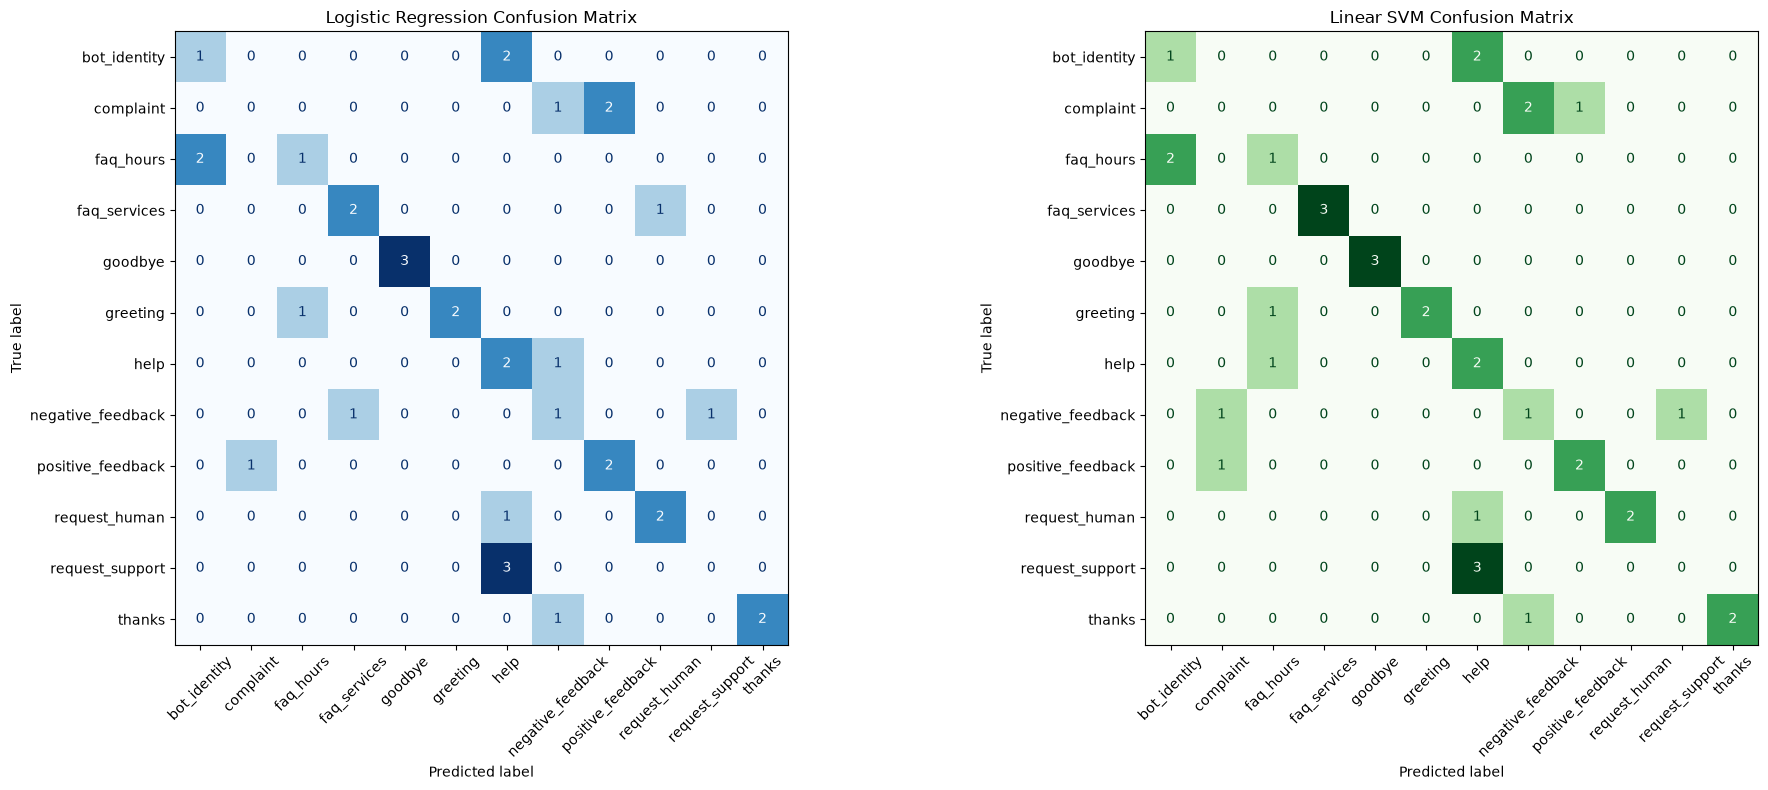

In [26]:
# Generate confusion matrices for both models

fig, axes = plt.subplots(1, 2, figsize=(20, 8))

# Logistic Regression confusion matrix

ConfusionMatrixDisplay.from_predictions(
    y_test,
    logistic_predictions,
    ax=axes[0],
    xticks_rotation=45,
    cmap="Blues",
    colorbar=False
)

axes[0].set_title("Logistic Regression Confusion Matrix")

# Linear SVM confusion matrix

ConfusionMatrixDisplay.from_predictions(
    y_test,
    svm_predictions,
    ax=axes[1],
    xticks_rotation=45,
    cmap="Greens",
    colorbar=False
)

axes[1].set_title("Linear SVM Confusion Matrix")

plt.tight_layout()
plt.show()



In [27]:
# Test the trained NLP models with new messages

test_messages = [
    "Hey, good morning",
    "I want to talk to a real person",
    "Your customer service is excellent",
    "I am very disappointed with your service",
    "Can you tell me your working hours?",
    "I cannot log into my account",
    "What services do you provide?",
    "Thank you for your assistance",
    "Who are you?",
    "I want to report a problem"
]

# Preprocess test messages

clean_test_messages = [
    preprocess_text(message) for message in test_messages
]

# Predict using Logistic Regression

logistic_test_predictions = logistic_model.predict(
    clean_test_messages
)

# Predict using Linear SVM

svm_test_predictions = svm_model.predict(
    clean_test_messages
)

# Display predictions

prediction_results = pd.DataFrame({
    "Original Message": test_messages,
    "Cleaned Message": clean_test_messages,
    "Logistic Regression": logistic_test_predictions,
    "Linear SVM": svm_test_predictions
})

display(prediction_results)

,Original Message,Cleaned Message,Logistic Regression,Linear SVM
0,"Hey, good morning",hey good morning,greeting,greeting
1,I want to talk to a real person,i want to talk to a real person,request_human,request_human
2,Your customer service is excellent,your customer service is excellent,positive_feedback,positive_feedback
3,I am very disappointed with your service,i am very disappointed with your service,positive_feedback,positive_feedback
4,Can you tell me your working hours?,can you tell me your working hours,help,faq_hours
5,I cannot log into my account,i cannot log into my account,request_support,request_support
6,What services do you provide?,what services do you provide,faq_services,faq_services
7,Thank you for your assistance,thank you for your assistance,thanks,thanks
8,Who are you?,who are you,bot_identity,bot_identity
9,I want to report a problem,i want to report a problem,complaint,complaint


In [28]:
# Entity Extraction (NER).

# Entity extraction using regular expressions

def extract_entities(text):

    entities = {}

    # Extract email addresses
    entities["EMAIL"] = re.findall(
        r"\b[A-Za-z0-9._%+-]+@[A-Za-z0-9.-]+\.[A-Za-z]{2,}\b",
        text
    )

    # Extract phone numbers
    entities["PHONE"] = re.findall(
        r"(?<!\d)(?:\+?\d{1,3}[- ]?)?\d{10}(?!\d)",
        text
    )

    # Extract dates (DD/MM/YYYY or DD-MM-YYYY)
    entities["DATE"] = re.findall(
        r"\b\d{1,2}[/-]\d{1,2}[/-]\d{4}\b",
        text
    )

    # Extract times (e.g. 10:30 AM)
    entities["TIME"] = re.findall(
        r"\b\d{1,2}:\d{2}\s?(?:AM|PM|am|pm)?\b",
        text
    )

    # Extract monetary amounts
    entities["AMOUNT"] = re.findall(
        r"(?:₹|Rs\.?|INR|\$)\s?\d+(?:,\d{3})*(?:\.\d{1,2})?",
        text,
        flags=re.IGNORECASE
    )

    # Extract common service-related keywords
    service_keywords = [
        "internet", "mobile", "billing", "payment",
        "account", "support", "subscription", "recharge",
        "connection", "service"
    ]

    entities["SERVICE"] = [
        word for word in service_keywords
        if re.search(r"\b" + re.escape(word) + r"\b", text, re.IGNORECASE)
    ]

    return entities


# Test entity extraction

sample_messages = [
    "Please contact me at test@example.com",
    "I need internet support for my account",
    "My appointment is on 25/11/2026 at 10:30 AM",
    "I paid ₹2,500 for my subscription",
    "Please call me at 9876543210"
]

for message in sample_messages:

    print("\nMessage:", message)
    print("Extracted entities:", extract_entities(message))


Message: Please contact me at test@example.com
Extracted entities: {'EMAIL': ['test@example.com'], 'PHONE': [], 'DATE': [], 'TIME': [], 'AMOUNT': [], 'SERVICE': []}

Message: I need internet support for my account
Extracted entities: {'EMAIL': [], 'PHONE': [], 'DATE': [], 'TIME': [], 'AMOUNT': [], 'SERVICE': ['internet', 'account', 'support']}

Message: My appointment is on 25/11/2026 at 10:30 AM
Extracted entities: {'EMAIL': [], 'PHONE': [], 'DATE': ['25/11/2026'], 'TIME': ['10:30 AM'], 'AMOUNT': [], 'SERVICE': []}

Message: I paid ₹2,500 for my subscription
Extracted entities: {'EMAIL': [], 'PHONE': [], 'DATE': [], 'TIME': [], 'AMOUNT': ['₹2,500'], 'SERVICE': ['subscription']}

Message: Please call me at 9876543210
Extracted entities: {'EMAIL': [], 'PHONE': ['9876543210'], 'DATE': [], 'TIME': [], 'AMOUNT': [], 'SERVICE': []}


In [29]:
# Load spaCy when the current environment permits its native dependencies.

# The rule-based extract_entities() function above remains available if spaCy cannot load.

try:
    import spacy
except ImportError as error:
    nlp = None
    print(f"spaCy is unavailable ({error}); use the rule-based extract_entities() function above.")
else:
    try:
        nlp = spacy.load("en_core_web_sm")
    except OSError as error:
        nlp = None
        print(f"spaCy model is unavailable ({error}); use the rule-based extract_entities() function above.")
    else:
        print("spaCy loaded successfully.")
        print("Model:", nlp.meta["name"])
        print("Version:", nlp.meta["version"])



spaCy loaded successfully.
Model: core_web_sm
Version: 3.8.0


In [30]:
import sys

print("Python executable:")
print(sys.executable)

print("\nPython version:")
print(sys.version)

Python executable:
c:\Users\umair\AppData\Local\Programs\Python\Python314\python.exe

Python version:
3.14.10 (tags/v3.14.10:b703b2c, Oct 25 2026, 17:36:52) [MSC v.1944 64 bit (AMD64)]


In [31]:
%pip install https://github.com/explosion/spacy-models/releases/download/en_core_web_sm-3.8.0/en_core_web_sm-3.8.0-py3-none-any.whl

     ---------------------------------------- 0.0/12.8 MB ? eta -:--:--
     -- ------------------------------------- 0.8/12.8 MB 3.1 MB/s eta 0:00:04
     --- ------------------------------------ 1.0/12.8 MB 2.1 MB/s eta 0:00:06
     --- ------------------------------------ 1.0/12.8 MB 2.1 MB/s eta 0:00:06
     ---- ----------------------------------- 1.6/12.8 MB 1.7 MB/s eta 0:00:07
     ------- -------------------------------- 2.4/12.8 MB 2.1 MB/s eta 0:00:05
     --------- ------------------------------ 2.9/12.8 MB 2.2 MB/s eta 0:00:05
     ---------- ----------------------------- 3.4/12.8 MB 2.2 MB/s eta 0:00:05
     ------------- -------------------------- 4.5/12.8 MB 2.5 MB/s eta 0:00:04
     ----------------- ---------------------- 5.5/12.8 MB 2.8 MB/s eta 0:00:03
     -------------------- ------------------- 6.6/12.8 MB 3.0 MB/s eta 0:00:03
     ---------------------- ----------------- 7.3/12.8 MB 3.1 MB/s eta 0:00:02
     --------------------------- ------------ 8.7/12.8 MB 3

In [32]:
%pip install --no-cache-dir --force-reinstall "spacy==3.8.18"

   ---------------------------------------- 0.0/15.2 MB ? eta -:--:--
   --- ------------------------------------ 1.3/15.2 MB 7.1 MB/s eta 0:00:02
   ----- ---------------------------------- 2.1/15.2 MB 5.1 MB/s eta 0:00:03
   ------ --------------------------------- 2.6/15.2 MB 4.9 MB/s eta 0:00:03
   ------- -------------------------------- 2.9/15.2 MB 4.0 MB/s eta 0:00:04
   ------- -------------------------------- 2.9/15.2 MB 4.0 MB/s eta 0:00:04
   -------- ------------------------------- 3.1/15.2 MB 2.7 MB/s eta 0:00:05
   -------- ------------------------------- 3.4/15.2 MB 2.2 MB/s eta 0:00:06
   --------- ------------------------------ 3.7/15.2 MB 2.1 MB/s eta 0:00:06
   ---------- ----------------------------- 3.9/15.2 MB 2.1 MB/s eta 0:00:06
   ----------- ---------------------------- 4.5/15.2 MB 2.0 MB/s eta 0:00:06
   ------------- -------------------------- 5.0/15.2 MB 2.1 MB/s eta 0:00:05
   -------------- ------------------------- 5.5/15.2 MB 2.1 MB/s eta 0:00:05
   ---

  You can safely remove it manually.
  You can safely remove it manually.
  You can safely remove it manually.
  You can safely remove it manually.


In [33]:
import spacy
print(spacy.__version__)

3.8.18


In [34]:
# Sample sentence for Named Entity Recognition

sample_text = """
Umair lives in Hyderabad.
He has an appointment on 25 November 2026.
The payment amount is Rs. 2500.
"""

# Process the text

doc = nlp(sample_text)

# Display extracted entities

print("Extracted Named Entities:\n")

for entity in doc.ents:
    print(
        "Entity:", entity.text,
        "| Entity Type:", entity.label_,
        "| Description:", spacy.explain(entity.label_)
    )

Extracted Named Entities:

Entity: Umair | Entity Type: ORG | Description: Companies, agencies, institutions, etc.
Entity: Hyderabad | Entity Type: GPE | Description: Countries, cities, states
Entity: 25 November 2026 | Entity Type: DATE | Description: Absolute or relative dates or periods
Entity: 2500 | Entity Type: CARDINAL | Description: Numerals that do not fall under another type


In [35]:
# Integrate Intent Recognition and Entity Extraction

# Combined NLP function: Intent Recognition + Entity Extraction

def understand_user_message(message):

    # Step 1: Preprocess the user message
    cleaned_message = preprocess_text(message)

    # Step 2: Predict intent using the best available model
    intent_prediction = logistic_model.predict([cleaned_message])[0]

    # Step 3: Predict intent using Linear SVM
    svm_prediction = svm_model.predict([cleaned_message])[0]

    # Step 4: Extract entities using custom rules
    rule_based_entities = extract_entities(message)

    # Step 5: Extract entities using spaCy
    doc = nlp(message)

    spacy_entities = []

    for entity in doc.ents:
        spacy_entities.append({
            "text": entity.text,
            "type": entity.label_,
            "description": spacy.explain(entity.label_)
        })

    # Step 6: Return combined results
    return {
        "original_message": message,
        "cleaned_message": cleaned_message,
        "predicted_intent_logistic": intent_prediction,
        "predicted_intent_svm": svm_prediction,
        "rule_based_entities": rule_based_entities,
        "spacy_entities": spacy_entities
    }


print("Combined NLP function created successfully.")

Combined NLP function created successfully.


In [36]:
# Test the combined NLP system

user_message = """
Hello, my name is Umair.
I need internet support in Hyderabad.
Please contact me at umair@hotmail.com.
My appointment is on 25 November 2026.
"""

result = understand_user_message(user_message)

print("USER MESSAGE:")
print(result["original_message"])

print("\nPREDICTED INTENT:")
print("Logistic Regression:", result["predicted_intent_logistic"])
print("Linear SVM:", result["predicted_intent_svm"])

print("\nRULE-BASED ENTITIES:")
print(result["rule_based_entities"])

print("\nSPACY ENTITIES:")

for entity in result["spacy_entities"]:
    print(entity)

USER MESSAGE:

Hello, my name is Umair.
I need internet support in Hyderabad.
Please contact me at umair@hotmail.com.
My appointment is on 25 November 2026.


PREDICTED INTENT:
Logistic Regression: request_support
Linear SVM: request_support

RULE-BASED ENTITIES:
{'EMAIL': ['umair@hotmail.com'], 'PHONE': [], 'DATE': [], 'TIME': [], 'AMOUNT': [], 'SERVICE': ['internet', 'support']}

SPACY ENTITIES:
{'text': 'Umair', 'type': 'ORG', 'description': 'Companies, agencies, institutions, etc.'}
{'text': 'Hyderabad', 'type': 'GPE', 'description': 'Countries, cities, states'}
{'text': '25 November 2026', 'type': 'DATE', 'description': 'Absolute or relative dates or periods'}


In [37]:
# Save NLP Model and Results

import joblib
from pathlib import Path

PROJECT_ROOT = Path(r"D:\Dynamic_AI_Chatbot_Project")

MODEL_DIR = PROJECT_ROOT / "models" / "nlp"
OUTPUT_DIR = PROJECT_ROOT / "outputs" / "nlp"

MODEL_DIR.mkdir(parents=True, exist_ok=True)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("NLP model and output folders created successfully.")
print("Model folder:", MODEL_DIR)
print("Output folder:", OUTPUT_DIR)

NLP model and output folders created successfully.
Model folder: D:\Dynamic_AI_Chatbot_Project\models\nlp
Output folder: D:\Dynamic_AI_Chatbot_Project\outputs\nlp


In [38]:
# Save both trained models

joblib.dump(
    logistic_model,
    MODEL_DIR / "intent_logistic_regression.pkl"
)

joblib.dump(
    svm_model,
    MODEL_DIR / "intent_linear_svm.pkl"
)

print("Both intent recognition models saved successfully.")

Both intent recognition models saved successfully.


In [40]:
# Save the test evaluation results

evaluation_results = pd.DataFrame([
    {
        "Model": "Logistic Regression",
        "Accuracy": accuracy_score(y_test, logistic_predictions),
        "Precision": precision_score(
            y_test, logistic_predictions,
            average="weighted", zero_division=0
        ),
        "Recall": recall_score(
            y_test, logistic_predictions,
            average="weighted", zero_division=0
        ),
        "F1 Score": f1_score(
            y_test, logistic_predictions,
            average="weighted", zero_division=0
        )
    },
    {
        "Model": "Linear SVM",
        "Accuracy": accuracy_score(y_test, svm_predictions),
        "Precision": precision_score(
            y_test, svm_predictions,
            average="weighted", zero_division=0
        ),
        "Recall": recall_score(
            y_test, svm_predictions,
            average="weighted", zero_division=0
        ),
        "F1 Score": f1_score(
            y_test, svm_predictions,
            average="weighted", zero_division=0
        )
    }
])

display(evaluation_results)

evaluation_results.to_csv(
    OUTPUT_DIR / "intent_model_evaluation.csv",
    index=False
)

print("NLP evaluation results saved successfully.")

,Model,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,0.500000,0.513889,0.500000,0.49062
1,Linear SVM,0.527778,0.569444,0.527778,0.53189


NLP evaluation results saved successfully.
